In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from joblib import Parallel, delayed
import fspiderman as sp
import batman
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import *
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
from HItargets_utils import hi_planets_by_name, filter_loc, filter_lambda

# Exoplanet Archive (to populate bias map)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-05_aggregate_short.csv')

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
K2_141b = hi_planets_by_name("K2-141 b")
period, incl, ecc, w, rp, r2, a, T_eff, a_AU = K2_141b.args

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from K2-141 data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

In [3]:
# Albedo assumptions

# Geometric albedo in the optical from Zieba 2022 (using Kepler, Spitzer data are not able to constrain the albedo at 4.5 µm). This is likely an overestimate. Zieba 2022 assumed A_B=A for Kepler.
Ag = 0.28

# Assuming grey Lambertian reflectance. PROBABLY UNPHYSICAL!
# A_B basically unrelated to A (MIR band integrated), mainly influenced by albedo in optical (lambda_max=630nm) + clouds/atmosphere
A_B = 3/2 * Ag # 0.42
# More physical would be:
# A_B = 0.1 # typical lava world in optical (Essack 2020), probably slight underestimate for bolometric.
# A_B = q * f_red * Ag_opt # with q~0.6 (more realistic for e.g. moon, Mercury), and f_red a spectral correction factor.

# ASSUMPTION (!)
# Model for band-integrated albedo in MIRI/LRS band (MIR)
A_model = ConstantBandAlbedo(.1) # Band-integrated albedo of rocky surface fixed to A=0.1 (small reflected part) in MIR
# A_model = ScaledBandAlbedo(1.) # Band-integrated albedo in MIR of rocky surface set to A=A_B (probably overestimate). Also, A_LRS and A_B are basically unrelated since >99% of stellar flux is below 5um - same actually goes for Spitzer: 98% under 3.7um.

In [4]:
# Filter to be used
instrument = "MIRI/LRS"
lrs_path = filter_loc(instrument)
lrs_range = filter_lambda(instrument)

## Detectability and parameter bias analysis (MIRI/LRS 5.0-10.5 um)

For K2-141b, MIRI/LRS 5.0-10.5 um has a detection error of 323 ppm per minute.


In [5]:
n_bins = 27 # number of bins in one orbit
minutes_binning = period*24*60/n_bins # bin width [minutes] - approx. 15min
sigma_1min      = 323. # detection error [ppm per minute], MIRI/LRS 5.0-10.5 um
n_orbits        = 3 # number of orbits observed (3 orbits has been done)


l1, l2 = lrs_range
stellar_grid = sp.stellar_grid.gen_grid(l1, l2, logg=4.5, response=lrs_path)

A_B_true = A_B  # 3/2 * Ag(Zieba2022) = 0.42;  under A = A_B this single albedo sets BOTH the reflected amplitude and the Bond albedo (dayside temperature)

# context for the bias-analysis functions imported from simple_bias_analysis.py (T_floor=200, bounds=(0.0, 0.6) by default)
cfg = FittingConfig(planet=K2_141b, stellar_grid=stellar_grid, filter_path=lrs_path,
                 l1=l1, l2=l2, A_=A_model,
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins,
                 reflected=True, u_B=u_B, u=u)


sigma_bin = cfg.sigma_bin # [ppm]
print(f"period = {period*24*60:.1f} min -> {n_bins} bins of {minutes_binning:.1f} min")
print(f"1-sigma per bin = {sigma_bin:.1f} ppm")

no stellar models provided, using blackbody approximation
period = 403.7 min -> 27 bins of 15.0 min
1-sigma per bin = 48.2 ppm


### 1. Pure Detectability

In [6]:
# Full phase curve (reflected + thermal). The naive curve uses full_PhaseCurve(insolation_model="naive")
t_k, pc_k, fp_k = full_PhaseCurve(K2_141b, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="hyperillum", u_B=u_B)
t_n, pc_n, fp_n = full_PhaseCurve(K2_141b, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="naive", u_B=u_B)

# Transit removed (phase modulation + occultation only) = reflected(no transit) + thermal(no transit), so the modulation is visible
_, lc_k, _ = full_PhaseCurve(K2_141b, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="hyperillum", u_B=u_B, include_transit=False)
_, lc_n, _ = full_PhaseCurve(K2_141b, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="naive",      u_B=u_B, include_transit=False)

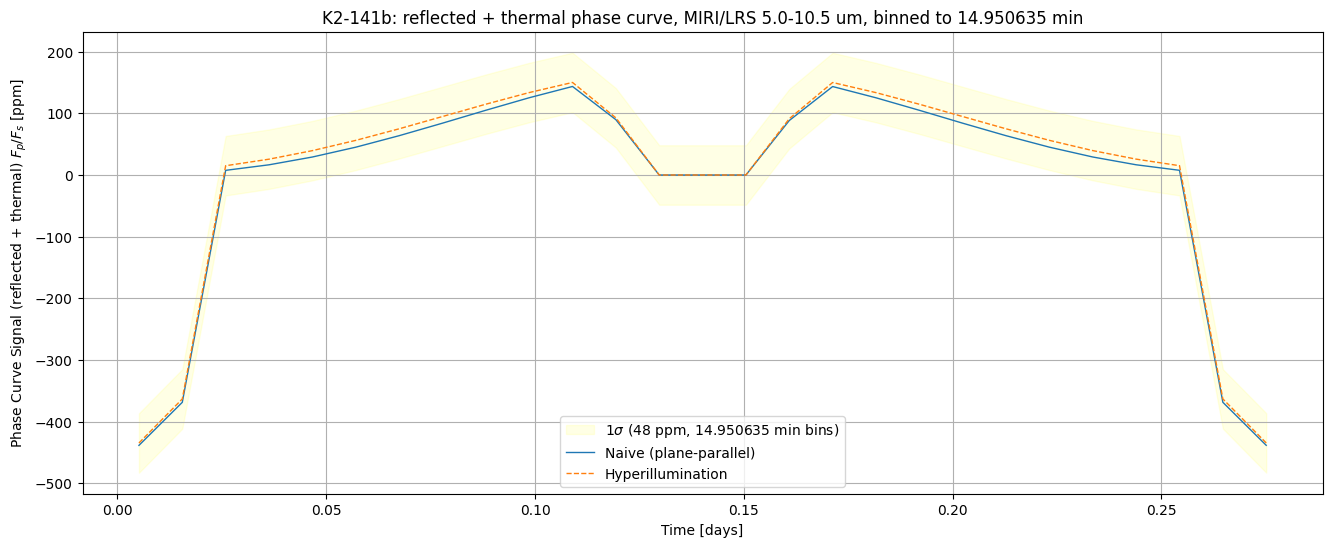

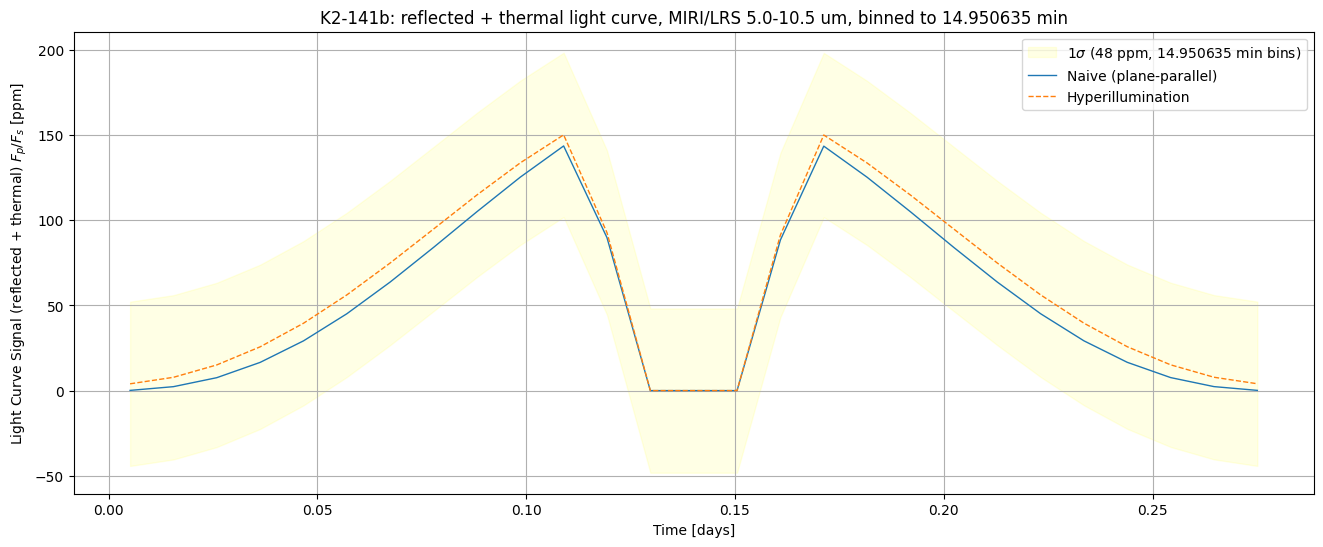

In [7]:
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color="yellow", alpha=0.1, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning:1f} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: reflected + thermal phase curve, MIRI/LRS 5.0-10.5 um, binned to {minutes_binning:1f} min")
plt.legend(); plt.grid()
plt.show()

tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color="yellow", alpha=0.1, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning:1f} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: reflected + thermal light curve, MIRI/LRS 5.0-10.5 um, binned to {minutes_binning:1f} min")
plt.legend(); plt.grid()
plt.show()

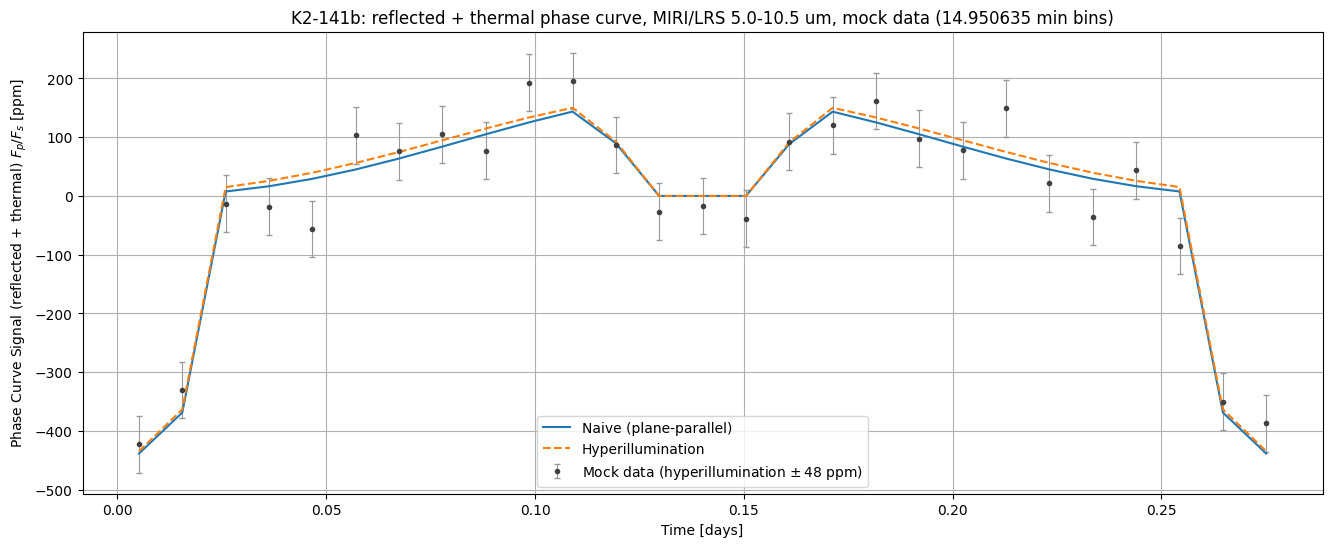

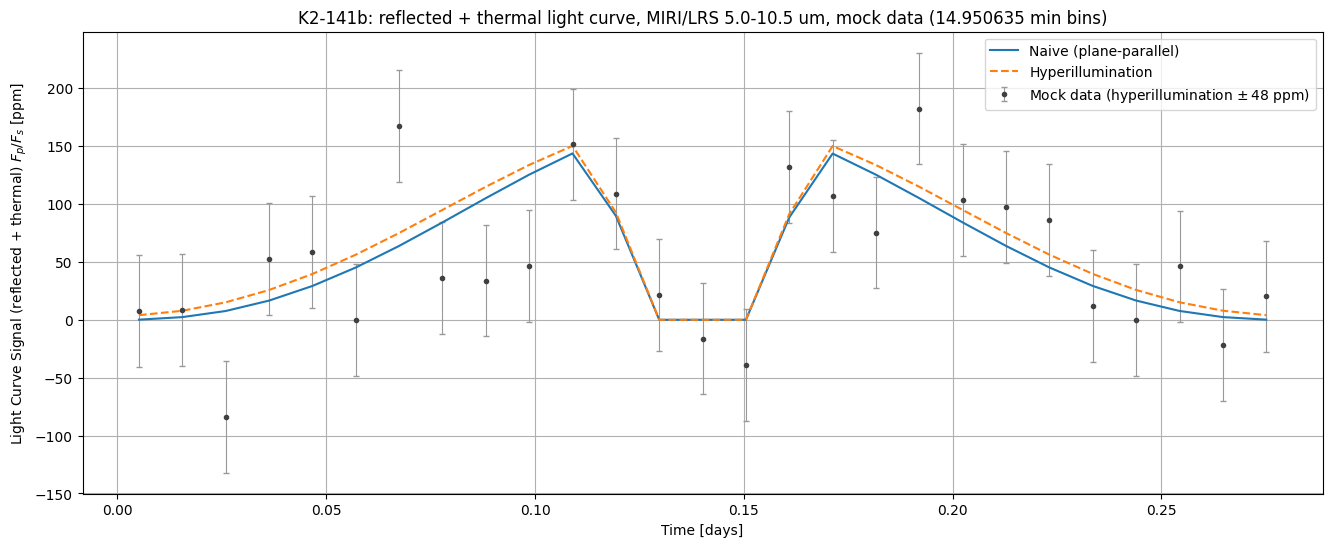

In [8]:
# Mock observation: at each binned time draw a data point ~ N(mean = hyperillum model, std = sigma_bin),
rng = np.random.default_rng(43)   # fixed seed -> reproducible mock data

# --- Phase curve ---
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)   # naive model, binned [ppm]
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)   # hyperillumination model, binned [ppm]
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)        # mock data ~ N(hyperillum, sigma_bin)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: reflected + thermal phase curve, MIRI/LRS 5.0-10.5 um, mock data ({minutes_binning:1f} min bins)")
plt.legend(); plt.grid()
plt.show()

# --- Light curve ---
tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: reflected + thermal light curve, MIRI/LRS 5.0-10.5 um, mock data ({minutes_binning:1f} min bins)")
plt.legend(); plt.grid()
plt.show()

### 2. Bias in recovered Bond albedo when hyperillumination is neglected - 1-Parameter Fit

In [9]:
# demo: fit the naive model to the hyperillumination truth and report the recovered-A_B bias
_, truth = model_pcurve(cfg, "hyperillum", A_B_true)

for free_offset in (True, False):
    A_fit, chi2, rms = fit_naive(cfg, truth, free_offset=free_offset)
    print(f"A_B: {A_B_true:.3f} -> {A_fit:.3f}  bias={A_fit-A_B_true:+.3f} "
          f"({100*(A_fit-A_B_true)/A_B_true:+.1f}%)  chi2={chi2:.3f}  "
          f"resid_rms={rms:.2f} ppm  significance={np.sqrt(chi2):.2f} sigma "
          f"({cfg.n_orbits} orbits, {cfg.n_bins} bins)")

A_B: 0.420 -> 0.376  bias=-0.044 (-10.5%)  chi2=0.132  resid_rms=3.37 ppm  significance=0.36 sigma (3 orbits, 27 bins)
A_B: 0.420 -> 0.274  bias=-0.146 (-34.7%)  chi2=0.301  resid_rms=5.09 ppm  significance=0.55 sigma (3 orbits, 27 bins)


free offset="False" not really meaningful since normalization has error...

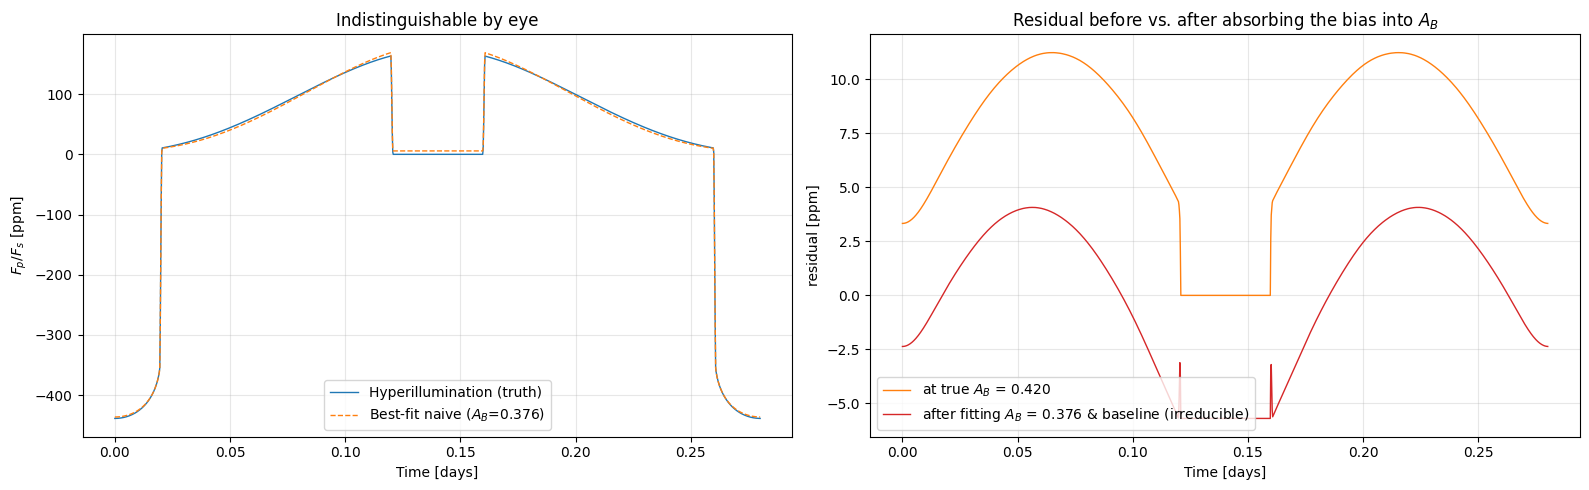

In [10]:
# before vs after absorbing the bias into A_B
t_, truth = model_pcurve(cfg, "hyperillum", A_B_true)
A_fit, _, _  = fit_naive(cfg, truth)
naive_0   = model_pcurve(cfg, "naive", A_B_true)[1]
naive_f   = model_pcurve(cfg, "naive", A_fit)[1]
naive_f   = naive_f + (truth - naive_f).mean()

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
# left: truth vs best-fit naive
ax[0].plot(t_, truth,   lw=1, label="Hyperillumination (truth)")
ax[0].plot(t_, naive_f, lw=1, ls="--", label=f"Best-fit naive ($A_B$={A_fit:.3f})")
ax[0].set_ylabel(r"$F_p/F_s$ [ppm]"); ax[0].set_xlabel("Time [days]")
ax[0].set_title("Indistinguishable by eye")
# right: both residuals combined on one axes
ax[1].plot(t_, truth - naive_0, lw=1, color="C1", label=rf"at true $A_B$ = {A_B_true:.3f}")
ax[1].plot(t_, truth - naive_f, lw=1, color="C3", label=rf"after fitting $A_B$ = {A_fit:.3f} & baseline (irreducible)")
ax[1].set_ylabel("residual [ppm]"); ax[1].set_xlabel("Time [days]")
ax[1].set_title(r"Residual before vs. after absorbing the bias into $A_B$")
for a_ in ax: a_.grid(alpha=.3); a_.legend()
fig.tight_layout()

### 3. Bias vs. true Bond albedo $A_B$

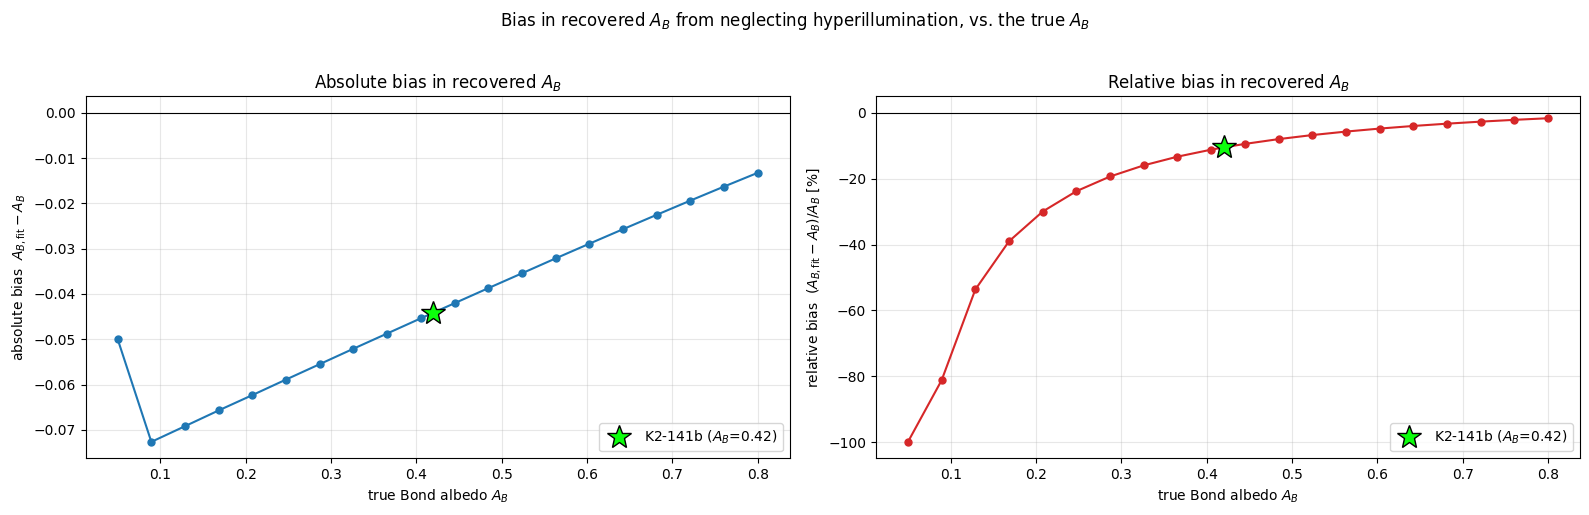

In [11]:
# Vary the TRUE Bond albedo and refit the naive model at each value (single K2-141b geometry,
# free baseline; free_offset=False is not meaningful here -- see 2.). Bias = A_fit - A_B_true.
A_B_grid = np.unique(np.concatenate([np.linspace(0.05, 0.80, 20), [A_B_true]]))

def bias_vs_AB(A_B_val):
    _, truth = model_pcurve(cfg, "hyperillum", A_B_val)
    A_fit, _, _ = fit_naive(cfg, truth, free_offset=True, bounds=(0., 1.))  # A_fit constrained to physical [0, 1]
    return A_fit - A_B_val

bias_abs = np.array(Parallel(n_jobs=-1, backend="loky")(delayed(bias_vs_AB)(A_B_val) for A_B_val in A_B_grid))
get_reusable_executor().shutdown(wait=True)   # free the memory SPIDERMAN leaks in the workers
bias_rel = 100. * bias_abs / A_B_grid
i0 = int(np.argmin(np.abs(A_B_grid - A_B_true)))   # nominal K2-141b point

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for a_, y, ylab, ttl, col in ((ax[0], bias_abs, r"absolute bias  $A_{B,\rm fit}-A_B$", "Absolute", "C0"),
                              (ax[1], bias_rel, r"relative bias  $(A_{B,\rm fit}-A_B)/A_B$ [%]", "Relative", "C3")):
    a_.axhline(0, color="k", lw=.8)
    a_.plot(A_B_grid, y, "o-", color=col, lw=1.5, ms=5)
    a_.plot(A_B_grid[i0], y[i0], "*", color="#0cff0c", ms=18, mec="k", label=f"K2-141b ($A_B$={A_B_true:.2f})")
    a_.set_xlabel(r"true Bond albedo $A_B$"); a_.set_ylabel(ylab)
    a_.set_title(ttl + r" bias in recovered $A_B$"); a_.grid(alpha=.3); a_.legend()
fig.suptitle("Bias in recovered $A_B$ from neglecting hyperillumination, vs. the true $A_B$", y=1.02)
fig.tight_layout()

At low true $A_B$ the best-fit naive albedo rails at the physical floor $A_{B,\rm fit}=0$ (the naive model is driven to zero albedo), so the absolute bias saturates at $-A_B$ and the relative bias at $-100\%$. The bias is negative throughout and its magnitude shrinks as $A_B\to1$.

### 4. In which regimes does hyperillumination matter? Bias map over (a/Rs, T_eff)

TODO: For careful evaluation of physical parameter space, add Roche limit to map

Theoretically the period P should be varied with (a/R★) for a fixed ρ★ = 3π(a/R★)³/(GP²). This is not necessary/answer-changing since the period is degenerate in the bias analysis.

In [12]:
# The bias in recovered A_B is a pure model-degeneracy quantity, so this map is independent of the noise level sigma and of the target's brightness. The (a/Rs, T_eff) cells are independent -> run them in parallel (processes; joblib).
a_rs_grid  = np.linspace(1.5, 4.0, 20)
T_eff_grid = np.linspace(3000., 6000., 10)
kw = dict(n_layers=40, n_lo=300, n_la=150)     # the 200 K T_floor in model_pcurve keeps the naive terminator spline stable at this resolution

flat = Parallel(n_jobs=-1, backend="loky")(
    delayed(bias_cell)(cfg, A_B_true, a_rs=ar, T_s=Ts, **kw) for Ts in T_eff_grid for ar in a_rs_grid)
bias_map = np.array(flat).reshape(len(T_eff_grid), len(a_rs_grid))
get_reusable_executor().shutdown(wait=True)  # free memory SPIDERMAN leaks in the workers before the next run

/opt/anaconda3/envs/PhaseCurves/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


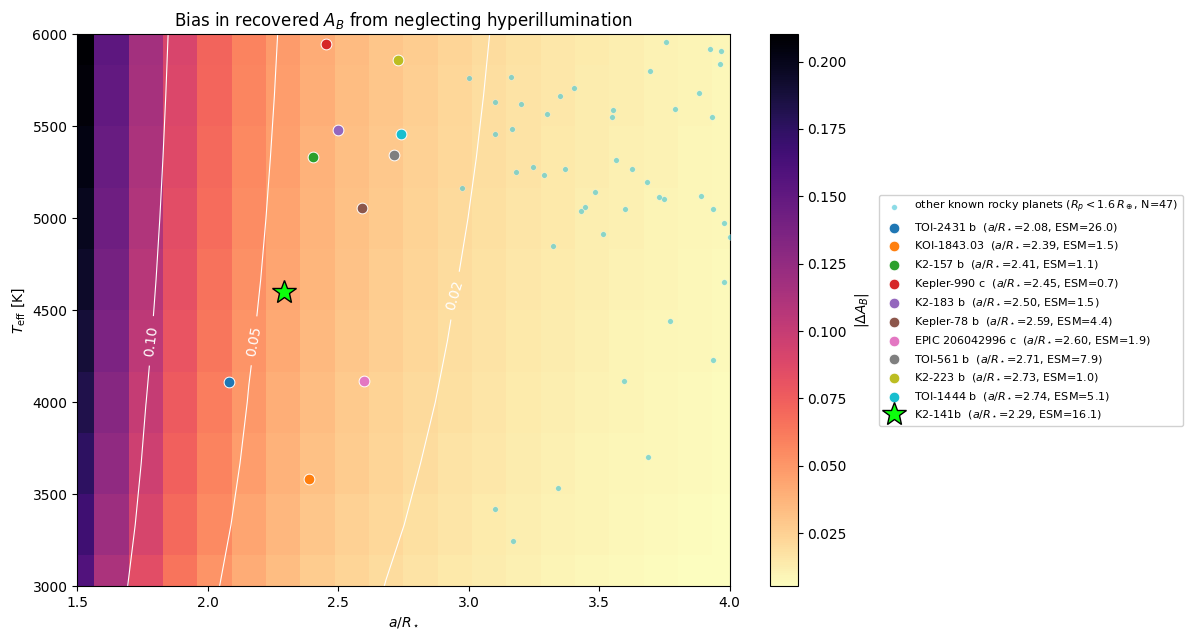

In [13]:
fig, ax = plt.subplots(figsize=(12, 6.5))
im = ax.pcolormesh(a_rs_grid, T_eff_grid, np.ma.masked_invalid(np.abs(bias_map)), cmap="magma_r", shading="auto")
cs = ax.contour(a_rs_grid, T_eff_grid, np.ma.masked_invalid(np.abs(bias_map)), levels=[0.02, 0.05, 0.10],
                colors="w", linewidths=.8)
ax.clabel(cs, fmt="%.2f")
overlay_planets(AGG, ax, "st_teff", (T_eff_grid[0], T_eff_grid[-1]))   # known ROCKY planets (NASA Exoplanet Archive, Rp < 1.6 R_Earth), labelled with a/Rs and ESM
ax.plot(a, T_eff, "*", color="#0cff0c", ms=18, mec="k", zorder=6, label=f"K2-141b  ($a/R_\\star$={(K2_141b.R/K2_141b.r2):.2f}, ESM={planet_esm(AGG, 'K2-141 b'):.1f})")
ax.set_facecolor("0.85")   # railed cells show as grey = "naive model breaks down"
ax.set_xlim(a_rs_grid[0], a_rs_grid[-1]); ax.set_ylim(T_eff_grid[0], T_eff_grid[-1])
ax.set_xlabel(r"$a/R_\star$"); ax.set_ylabel(r"$T_{\rm eff}$ [K]")
ax.set_title(r"Bias in recovered $A_B$ from neglecting hyperillumination")
fig.colorbar(im, ax=ax, label=r"$|\Delta A_B|$")
ax.legend(loc="center left", bbox_to_anchor=(1.22, 0.5), fontsize=8, framealpha=.9)
fig.tight_layout()

### 5. In which regimes does hyperillumination matter? Bias map over (a/Rs, Rp/Rs)

In [14]:
a_rs_grid  = np.linspace(1.5, 4.0, 20)
rp_rs_grid = np.linspace(0.01, 0.025, 10)
kw = dict(n_layers=40, n_lo=300, n_la=150)     # the 200 K T_floor in model_pcurve keeps the naive terminator spline stable at this resolution

flat = Parallel(n_jobs=-1, backend="loky")(
    delayed(bias_cell)(cfg, A_B_true, a_rs=ar, rp_rs=rpp, **kw) for rpp in rp_rs_grid for ar in a_rs_grid)
bias_map = np.array(flat).reshape(len(rp_rs_grid), len(a_rs_grid))
get_reusable_executor().shutdown(wait=True)  # free memory SPIDERMAN leaks in the workers before the next run

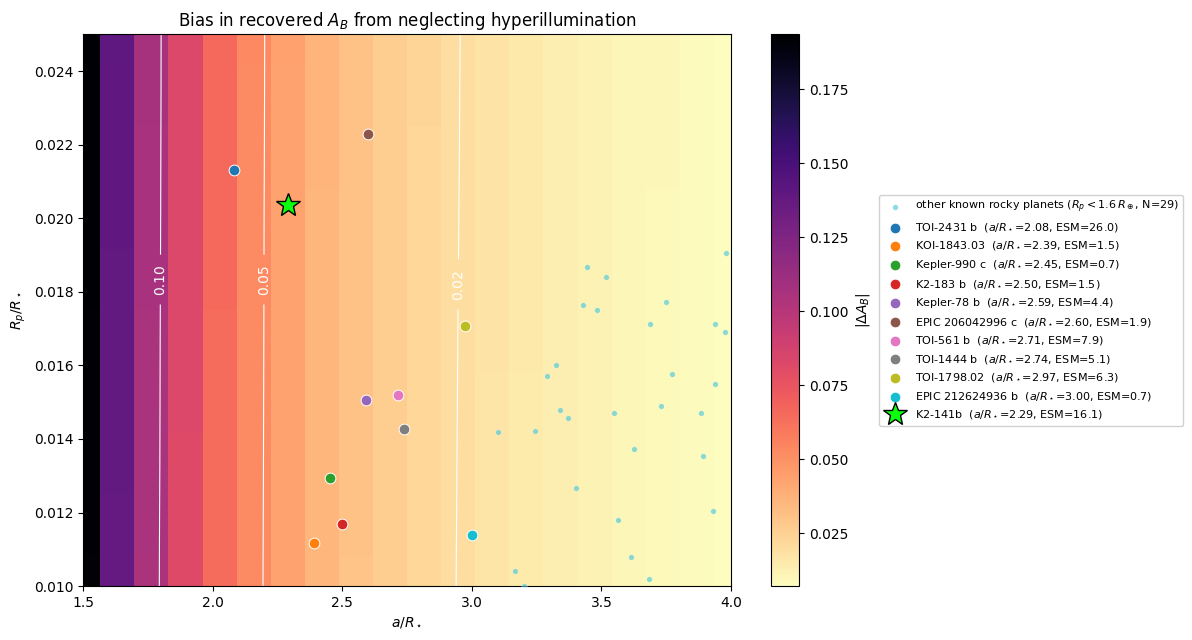

In [15]:
fig, ax = plt.subplots(figsize=(12, 6.5))
im = ax.pcolormesh(a_rs_grid, rp_rs_grid, np.ma.masked_invalid(np.abs(bias_map)), cmap="magma_r", shading="auto")
cs = ax.contour(a_rs_grid, rp_rs_grid, np.ma.masked_invalid(np.abs(bias_map)), levels=[0.02, 0.05, 0.10],
                colors="w", linewidths=.8)
ax.clabel(cs, fmt="%.2f")
overlay_planets(AGG, ax, "pl_ratror", (rp_rs_grid[0], rp_rs_grid[-1]))   # known ROCKY planets (NASA Exoplanet Archive, Rp < 1.6 R_Earth), labelled with a/Rs and ESM
ax.plot(a, rp, "*", color="#0cff0c", ms=18, mec="k", zorder=6, label=f"K2-141b  ($a/R_\\star$={(K2_141b.R/K2_141b.r2):.2f}, ESM={planet_esm(AGG, 'K2-141 b'):.1f})")
ax.set_facecolor("0.85")   # railed cells show as grey = "naive model breaks down"
ax.set_xlim(a_rs_grid[0], a_rs_grid[-1]); ax.set_ylim(rp_rs_grid[0], rp_rs_grid[-1])
ax.set_xlabel(r"$a/R_\star$"); ax.set_ylabel(r"$R_p/R_\star$")
ax.set_title(r"Bias in recovered $A_B$ from neglecting hyperillumination")
fig.colorbar(im, ax=ax, label=r"$|\Delta A_B|$")
ax.legend(loc="center left", bbox_to_anchor=(1.22, 0.5), fontsize=8, framealpha=.9)
fig.tight_layout()

Bias is negative throughout the map.